# Évora — ANNIE × FLAME Integration v3

This notebook is the reproducible integration workflow used for the Évora paper.

**Analytical principle:** keep separate the three levels defined in the paper:
1. textual/formulaic recurrence;
2. observed distribution in relation to actors, roles, institutions, transaction type, chronology, and notarial authorship;
3. historical/diplomatic interpretation.

`BCSL_Evora.jsonl` contains the **human-validated** Barletta annotations used in the paper.  
The FLAME input used here is the final run with the current standard configuration (`ngram=6`, `n_out=1`).

## Required files

Place in the notebook directory:

- `BCSL_Evora.jsonl`
- `Output_Default_Flame.zip`

The FLAME ZIP must contain:
- `dist_mat.npz`
- `similarity_heatmap.html`
- `text_comparisons_01.html`
- the other FLAME reports produced by the same run.

The notebook verifies the 16-document order directly against the FLAME heatmap before integrating the matrices.

In [ ]:
import json, re, base64, zipfile, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

In [ ]:
BASE = Path(".")
BCSL_JSONL = BASE / "BCSL_Evora.jsonl"
FLAME_ZIP = BASE / "Output_Default_Flame.zip"
FLAME_DIR = BASE / "flame_output_default"

DOC_IDS = [
    "BCSL_14","BCSL_18","BCSL_19","BCSL_20","BCSL_21","BCSL_22","BCSL_23",
    "BCSL_25","BCSL_26","BCSL_27","BCSL_29","BCSL_30","BCSL_31","BCSL_33",
    "BCSL_35","BCSL_36"
]

FLAME_FILENAMES = [
    "BCSL_14r.txt","BCSL_18r.txt","BCSL_19r.txt","BCSL_20r.txt","BCSL_21r.txt",
    "BCSL_22r.txt","BCSL_23r.txt","BCSL_25r_1.txt","BCSL_26r.txt","BCSL_27r.txt",
    "BCSL_29r.txt","BCSL_30r.txt","BCSL_31r.txt","BCSL_33r.txt","BCSL_35r.txt",
    "BCSL_36r.txt"
]

## 1. Load Barletta annotations

The integration is based on document-level annotation data from `BCSL_Evora.jsonl`. Clause spans are preserved exactly; document-level presence is also calculated so that repeated occurrences of the same clause do not inflate distributional comparisons.


In [ ]:
def load_jsonl(path):
    out = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                out.append(json.loads(line))
    return out

bcsl = load_jsonl(BCSL_JSONL)
assert len(bcsl) == 16


In [ ]:
CLAUSE_LABELS = [
    "CAPITULUM","DEFENSIO","FIDEJUSSIO","IURAMENTUM","OBLIGATIO",
    "PACTUM_REVOCATIONIS","PRECARIUM","PROROGATIO_IURISDICTIONIS",
    "RENUNTIATIO","RESTITUTIO_CUM_MELIORATIONE","RESTITUTIO_IN_INTEGRUM",
    "RESTRICTIO_ALIENATIONIS","SANCTIO_NEGATIVA","STIPULATIO"
]

DISPLAY = {
    "CAPITULUM":"capitulum",
    "DEFENSIO":"defensio",
    "FIDEJUSSIO":"fideiussio",
    "IURAMENTUM":"iuramentum",
    "OBLIGATIO":"obligatio",
    "PACTUM_REVOCATIONIS":"pactum revocationis",
    "PRECARIUM":"precarium",
    "PROROGATIO_IURISDICTIONIS":"prorogatio iurisdictionis",
    "RENUNTIATIO":"renuntiatio",
    "RESTITUTIO_CUM_MELIORATIONE":"restitutio cum melioratione",
    "RESTITUTIO_IN_INTEGRUM":"restitutio in integrum",
    "RESTRICTIO_ALIENATIONIS":"restrictio alienationis",
    "SANCTIO_NEGATIVA":"sanctio negativa",
    "STIPULATIO":"stipulatio"
}

rows = []
span_rows = []
for doc_id, obj in zip(DOC_IDS, bcsl):
    counts = collections.Counter(s["label"] for s in obj["spans"])
    rows.append({"document": doc_id, **{DISPLAY[x]: counts[x] for x in CLAUSE_LABELS}})
    for s in obj["spans"]:
        if s["label"] in CLAUSE_LABELS:
            span_rows.append({
                "document": doc_id,
                "clause": DISPLAY[s["label"]],
                "start": s["start"],
                "end": s["end"],
                "text": obj["text"][s["start"]:s["end"]]
            })

clause_counts = pd.DataFrame(rows).set_index("document")
clause_presence = (clause_counts > 0).astype(int)
display(clause_presence)
display(clause_presence.sum().sort_values(ascending=False))


,capitulum,defensio,fideiussio,iuramentum,obligatio,pactum revocationis,precarium,prorogatio iurisdictionis,renuntiatio,restitutio cum melioratione,restitutio in integrum,restrictio alienationis,sanctio negativa,stipulatio
document,,,,,,,,,,,,,,
BCSL_14,0,1,0,1,1,0,1,0,1,0,0,0,1,0
BCSL_18,0,1,1,1,1,0,1,0,1,0,0,0,1,1
BCSL_19,0,1,0,1,1,0,1,0,1,0,0,0,1,1
BCSL_20,0,1,0,1,1,1,0,0,1,0,0,0,1,1
BCSL_21,0,1,1,1,1,0,1,0,1,0,0,0,1,1
BCSL_22,1,1,0,1,1,0,0,1,1,0,1,0,1,0
BCSL_23,0,1,0,1,1,0,0,0,1,0,1,0,1,1
BCSL_25,1,1,0,1,1,0,0,1,1,1,0,1,1,1
BCSL_26,0,1,0,1,1,0,1,0,1,0,0,0,1,0


obligatio                      16
iuramentum                     16
sanctio negativa               16
renuntiatio                    16
defensio                       15
stipulatio                      9
prorogatio iurisdictionis       8
precarium                       7
capitulum                       6
restrictio alienationis         6
restitutio in integrum          5
restitutio cum melioratione     3
fideiussio                      2
pactum revocationis             1
dtype: int64

## 2. Load and validate the final FLAME run

The notebook extracts the FLAME ZIP, reconstructs the sparse similarity matrix from `dist_mat.npz`, verifies that it matches the matrix embedded in `similarity_heatmap.html`, and checks the exact document order.

In [ ]:
FLAME_DIR.mkdir(exist_ok=True)
with zipfile.ZipFile(FLAME_ZIP, "r") as zf:
    zf.extractall(FLAME_DIR)

NPZ_PATH = FLAME_DIR / "dist_mat.npz"

npz = np.load(NPZ_PATH)
M = csr_matrix(
    (npz["data"], npz["indices"], npz["indptr"]),
    shape=tuple(npz["shape"].tolist())
).toarray().astype(float)

assert M.shape == (16, 16)

heatmap_html = (FLAME_DIR / "similarity_heatmap.html").read_text(encoding="utf-8")

# Recover document order from the FLAME heatmap.
x_match = re.search(r'"x":\[(.*?)\],"y":', heatmap_html)
assert x_match is not None
heatmap_order = json.loads("[" + x_match.group(1) + "]")
assert heatmap_order == FLAME_FILENAMES

# Recover and compare the matrix embedded in the heatmap.
m = re.search(r'"z":\{"dtype":"f4","bdata":"([^"]+)","shape":"16, 16"\}', heatmap_html)
assert m is not None
raw = base64.b64decode(m.group(1).replace("\\u002f", "/"))
M_html = np.frombuffer(raw, dtype=np.float32).reshape(16,16).astype(float)
assert np.allclose(M, M_html)

comparison_html = (FLAME_DIR / "text_comparisons_01.html").read_text(encoding="utf-8")
threshold_match = re.search(r'data-initial-threshold="([0-9.]+)"', comparison_html)
threshold = float(threshold_match.group(1)) if threshold_match else np.nan

# Numerical noise can make the diagonal fractionally > 1.
S = np.clip(M, 0, 1)
np.fill_diagonal(S, 1)

print("FLAME matrix:", S.shape)
print("Document order verified:", heatmap_order)
print("Automatic Otsu threshold:", threshold)
print("Off-diagonal min:", S[np.triu_indices(16, 1)].min())
print("Off-diagonal mean:", S[np.triu_indices(16, 1)].mean())
print("Off-diagonal max:", S[np.triu_indices(16, 1)].max())

FLAME matrix: (16, 16)
Document order verified: ['BCSL_14r.txt', 'BCSL_18r.txt', 'BCSL_19r.txt', 'BCSL_20r.txt', 'BCSL_21r.txt', 'BCSL_22r.txt', 'BCSL_23r.txt', 'BCSL_25r_1.txt', 'BCSL_26r.txt', 'BCSL_27r.txt', 'BCSL_29r.txt', 'BCSL_30r.txt', 'BCSL_31r.txt', 'BCSL_33r.txt', 'BCSL_35r.txt', 'BCSL_36r.txt']
Automatic Otsu threshold: 0.333625853061676
Off-diagonal min: 0.03887580707669258
Off-diagonal mean: 0.09283608682453633
Off-diagonal max: 0.33440402150154114


### Final FLAME run parameters

- n-gram window: **6**
- n-out positions: **1**
- minimum text length: **150 characters**
- file suffix: `.txt`
- maximum documents: **10,000**
- similarity threshold: **auto**
- auto-threshold method: **Otsu**

The automatic threshold recovered from the actual Barletta run is printed above.  
The complete pairwise matrix, not only the pairs above the reporting threshold, is used for downstream integration.

## 3. Contextual metadata

The contextual metadata record chronology, notarial authorship, transaction type, and the roles of documentary actors and institutions. They provide contextual variables for comparison with the distribution of annotated clauses.

In [ ]:
metadata = pd.DataFrame([
["BCSL_14",1393,"Palmerius de Fasano","Sale"],
["BCSL_18",1409,"Matheus notarii Iacobi de Barolo","Sale"],
["BCSL_19",1412,"Matheus notarii Iacobi de Barolo","Sale"],
["BCSL_20",1413,"Matheus notarii Iacobi de Barolo","Sale"],
["BCSL_21",1417,"Leucius de Urso de Trano","Sale"],
["BCSL_22",1417,"Cobellus notarii Mathei de Barolo","Exchange"],
["BCSL_23",1418,"Cobellus notarii Mathei de Barolo","Sale"],
["BCSL_25",1433,"Cobellus notarii Mathei de Barolo","Grant"],
["BCSL_26",1446,"Paulus de Castrisio de Barolo","Sale"],
["BCSL_27",1447,"Cobellus notarii Mathei de Piczis de Barolo","Sale"],
["BCSL_29",1460,"Santillus magistri Viti de Barolo","Grant"],
["BCSL_30",1470,"Santillus magistri Viti de Barolo","Grant"],
["BCSL_31",1474,"Antonius magistri Viti de Barolo","Grant"],
["BCSL_33",1476,"Franciscus Cappecta de Barolo","Sale"],
["BCSL_35",1485,"Stephanus Granata de Barulo","Grant"],
["BCSL_36",1486,"Ioannes de Geraldinis de Barulo","Grant"],
], columns=["document","year","notary","transaction_type"]).set_index("document")

metadata["notary_group"] = metadata["notary"]
metadata.loc[["BCSL_22","BCSL_23","BCSL_25","BCSL_27"], "notary_group"] = "Cobellus notarii Mathei de Piczis de Barolo"

for c in ["grant_subject_to_annual_rent","institution_as_transferor_or_grantor",
          "collective_monastic_action","institution_as_acquirer",
          "female_lay_transferor_with_mundualdus"]:
    metadata[c] = 0

metadata.loc[["BCSL_25","BCSL_29","BCSL_30","BCSL_31","BCSL_35","BCSL_36"], "grant_subject_to_annual_rent"] = 1
metadata.loc[["BCSL_22","BCSL_25","BCSL_29","BCSL_30","BCSL_31","BCSL_33","BCSL_35","BCSL_36"], "institution_as_transferor_or_grantor"] = 1
metadata.loc[["BCSL_22","BCSL_25","BCSL_29","BCSL_31","BCSL_35","BCSL_36"], "collective_monastic_action"] = 1
metadata.loc[["BCSL_14","BCSL_18","BCSL_19","BCSL_20","BCSL_21"], "institution_as_acquirer"] = 1
metadata.loc[["BCSL_18","BCSL_21","BCSL_27"], "female_lay_transferor_with_mundualdus"] = 1

integrated = metadata.join(clause_presence)
display(integrated)


,year,notary,transaction_type,notary_group,grant_subject_to_annual_rent,institution_as_transferor_or_grantor,collective_monastic_action,institution_as_acquirer,female_lay_transferor_with_mundualdus,capitulum,defensio,fideiussio,iuramentum,obligatio,pactum revocationis,precarium,prorogatio iurisdictionis,renuntiatio,restitutio cum melioratione,restitutio in integrum,restrictio alienationis,sanctio negativa,stipulatio
document,,,,,,,,,,,,,,,,,,,,,,,
BCSL_14,1393,Palmerius de Fasano,Sale,Palmerius de Fasano,0,0,0,1,0,0,1,0,1,1,0,1,0,1,0,0,0,1,0
BCSL_18,1409,Matheus notarii Iacobi de Barolo,Sale,Matheus notarii Iacobi de Barolo,0,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1
BCSL_19,1412,Matheus notarii Iacobi de Barolo,Sale,Matheus notarii Iacobi de Barolo,0,0,0,1,0,0,1,0,1,1,0,1,0,1,0,0,0,1,1
BCSL_20,1413,Matheus notarii Iacobi de Barolo,Sale,Matheus notarii Iacobi de Barolo,0,0,0,1,0,0,1,0,1,1,1,0,0,1,0,0,0,1,1
BCSL_21,1417,Leucius de Urso de Trano,Sale,Leucius de Urso de Trano,0,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1
BCSL_22,1417,Cobellus notarii Mathei de Barolo,Exchange,Cobellus notarii Mathei de Piczis de Barolo,0,1,1,0,0,1,1,0,1,1,0,0,1,1,0,1,0,1,0
BCSL_23,1418,Cobellus notarii Mathei de Barolo,Sale,Cobellus notarii Mathei de Piczis de Barolo,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,1,0,1,1
BCSL_25,1433,Cobellus notarii Mathei de Barolo,Grant,Cobellus notarii Mathei de Piczis de Barolo,1,1,1,0,0,1,1,0,1,1,0,0,1,1,1,0,1,1,1
BCSL_26,1446,Paulus de Castrisio de Barolo,Sale,Paulus de Castrisio de Barolo,0,0,0,0,0,0,1,0,1,1,0,1,0,1,0,0,0,1,0


## 4. FLAME ordering

The notebook computes document distances as `1 − cosine similarity` and applies average-linkage hierarchical clustering to determine the order of the documents in the heatmaps.

['BCSL_14', 'BCSL_21', 'BCSL_30', 'BCSL_25', 'BCSL_35', 'BCSL_36', 'BCSL_29', 'BCSL_31', 'BCSL_26', 'BCSL_27', 'BCSL_33', 'BCSL_22', 'BCSL_23', 'BCSL_18', 'BCSL_19', 'BCSL_20']


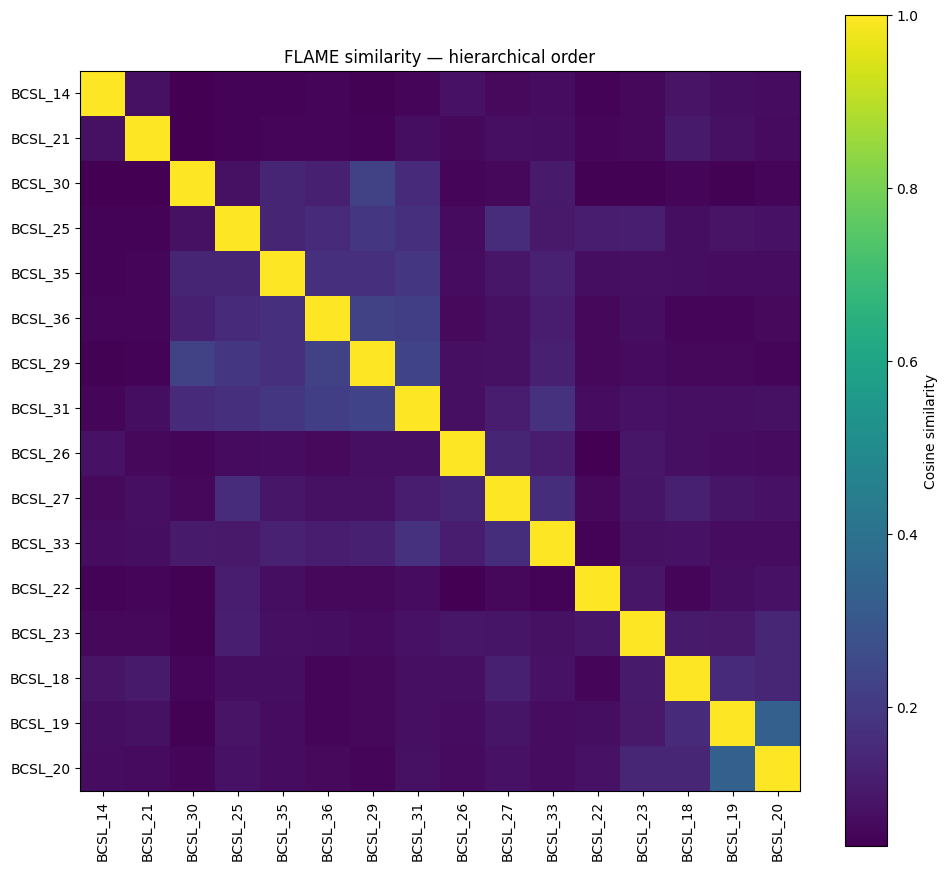

In [ ]:
D = 1 - S
D = (D + D.T) / 2
np.fill_diagonal(D, 0)
Z = linkage(squareform(D, checks=False), method="average")
order = [DOC_IDS[i] for i in leaves_list(Z)]
print(order)

fig = plt.figure(figsize=(10,9))
ax = fig.add_subplot(111)
idx = [DOC_IDS.index(d) for d in order]
im = ax.imshow(S[np.ix_(idx,idx)])
ax.set_xticks(range(16)); ax.set_xticklabels(order, rotation=90)
ax.set_yticks(range(16)); ax.set_yticklabels(order)
fig.colorbar(im, ax=ax, label="Cosine similarity")
ax.set_title("FLAME similarity — hierarchical order")
fig.tight_layout()
plt.show()


## 5. Clause matrix in FLAME order


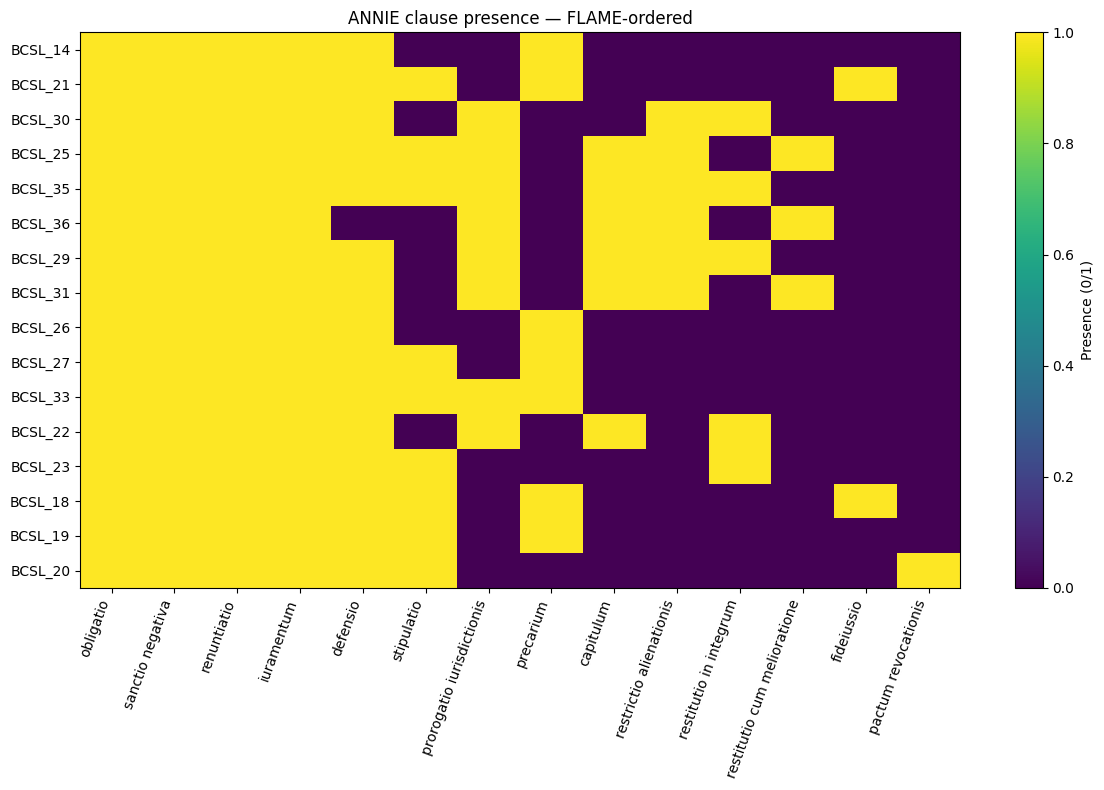

In [ ]:
cols = [
"obligatio","sanctio negativa","renuntiatio","iuramentum","defensio","stipulatio",
"prorogatio iurisdictionis","precarium","capitulum","restrictio alienationis",
"restitutio in integrum","restitutio cum melioratione","fideiussio","pactum revocationis"
]
X = clause_presence.loc[order, cols].values

fig = plt.figure(figsize=(12,8))
ax = fig.add_subplot(111)
im = ax.imshow(X, aspect="auto")
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=70, ha="right")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
fig.colorbar(im, ax=ax, label="Presence (0/1)")
ax.set_title("ANNIE clause presence — FLAME-ordered")
fig.tight_layout()
plt.show()


## 6. Integrated context × clause matrix


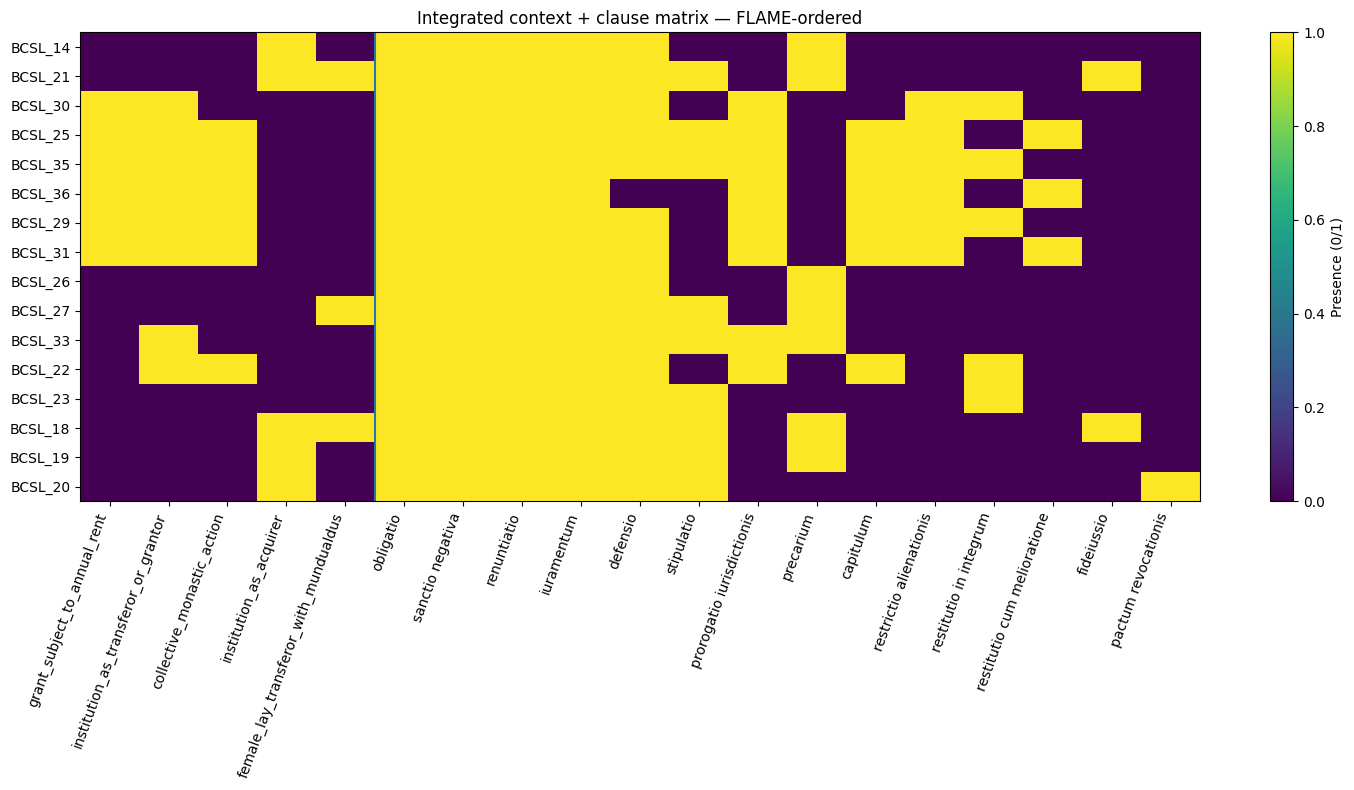

In [ ]:
context_cols = [
"grant_subject_to_annual_rent",
"institution_as_transferor_or_grantor",
"collective_monastic_action",
"institution_as_acquirer",
"female_lay_transferor_with_mundualdus"
]
all_cols = context_cols + cols
X = integrated.loc[order, all_cols].astype(int).values

fig = plt.figure(figsize=(15,8))
ax = fig.add_subplot(111)
im = ax.imshow(X, aspect="auto")
ax.set_xticks(range(len(all_cols))); ax.set_xticklabels(all_cols, rotation=70, ha="right")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.axvline(4.5, linewidth=1.5)
fig.colorbar(im, ax=ax, label="Presence (0/1)")
ax.set_title("Integrated context + clause matrix — FLAME-ordered")
fig.tight_layout()
plt.show()


## 7. Pairwise structural similarity vs clause-repertoire similarity

For each of the 120 unique document pairs, the notebook compares:

- the FLAME cosine similarity;
- the Jaccard similarity of the 14-clause presence/absence profiles derived from the validated ANNIE annotations.

Spearman's rho measures whether document pairs that are more similar in FLAME also tend to share a more similar repertoire of diplomatic clauses.

The 120 pairs are **not independent observations**, because every document occurs in 15 different pairs. For that reason, the ordinary Spearman p-value is not used as the inferential result. A document-label permutation test is performed in the next step.

Number of unique document pairs: 120
Observed Spearman rho: 0.49221104050967884


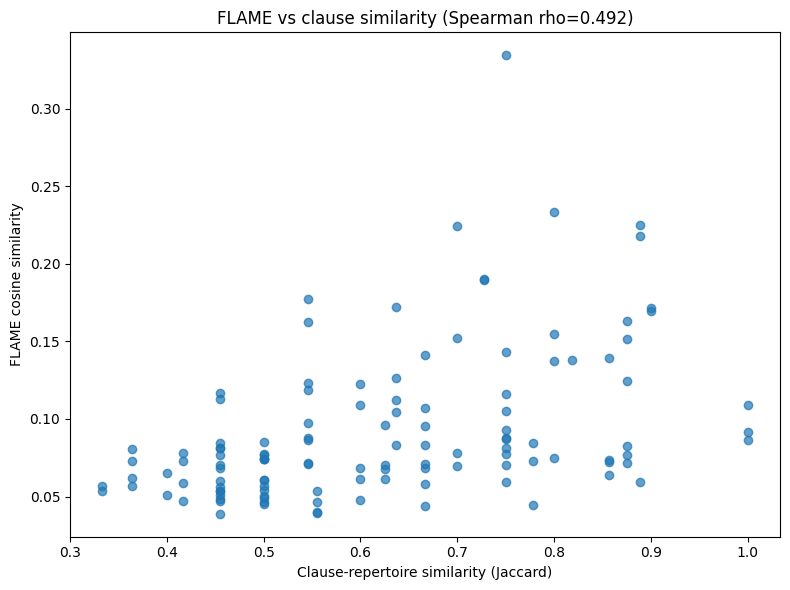

In [ ]:
C = clause_presence.loc[DOC_IDS].values.astype(bool)
pairs = [(i, j) for i in range(len(DOC_IDS)) for j in range(i + 1, len(DOC_IDS))]

def jaccard_vector(matrix):
    values = []
    for i, j in pairs:
        intersection = int((matrix[i] & matrix[j]).sum())
        union = int((matrix[i] | matrix[j]).sum())
        values.append(intersection / union if union else np.nan)
    return np.asarray(values, dtype=float)

flame_vec = np.asarray([S[i, j] for i, j in pairs], dtype=float)
jaccard_vec = jaccard_vector(C)

pairwise = pd.DataFrame({
    "document_1": [DOC_IDS[i] for i, j in pairs],
    "document_2": [DOC_IDS[j] for i, j in pairs],
    "flame_cosine_similarity": flame_vec,
    "clause_jaccard_similarity": jaccard_vec,
})

observed_rho = float(
    spearmanr(
        pairwise["flame_cosine_similarity"],
        pairwise["clause_jaccard_similarity"]
    ).statistic
)

print("Number of unique document pairs:", len(pairwise))
print("Observed Spearman rho:", observed_rho)

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111)
ax.scatter(
    pairwise["clause_jaccard_similarity"],
    pairwise["flame_cosine_similarity"],
    alpha=.7
)
ax.set_xlabel("Clause-repertoire similarity (Jaccard)")
ax.set_ylabel("FLAME cosine similarity")
ax.set_title(f"FLAME vs clause similarity (Spearman rho={observed_rho:.3f})")
fig.tight_layout()
plt.show()

### 7.1 Document-label permutation test (10,000 random permutations)

This is a **Monte Carlo permutation test**.

The observed alignment between the FLAME matrix and the ANNIE clause profiles is first measured with Spearman's rho. To construct the null distribution, the 16 ANNIE document labels are then randomly reassigned while the FLAME matrix remains fixed. After each reassignment:

1. all 120 Jaccard similarities are recomputed;
2. Spearman's rho with the fixed FLAME similarities is recomputed.

The reassignment is performed at **document level**, not by shuffling the 120 pairs independently. This preserves the dependence structure created by the fact that the same document appears in multiple pairs.

There are `16!` possible document-label permutations, far too many to enumerate exhaustively. The test therefore draws **10,000 random permutations** from that much larger set. This random approximation is what “Monte Carlo” means here.

A fixed random seed (`42`) is used so that the same 10,000 permutations and the same result can be reproduced. The empirical two-sided p-value uses the standard `+1` correction:

`p = (number of permuted |rho| >= observed |rho| + 1) / (number of permutations + 1)`.

In [ ]:
N_PERMUTATIONS = 10_000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)
permuted_rhos = np.empty(N_PERMUTATIONS, dtype=float)

for k in range(N_PERMUTATIONS):
    permuted_rows = rng.permutation(len(DOC_IDS))
    permuted_clause_profiles = C[permuted_rows]
    permuted_jaccard = jaccard_vector(permuted_clause_profiles)

    permuted_rhos[k] = spearmanr(
        flame_vec,
        permuted_jaccard
    ).statistic

n_as_or_more_extreme = int(
    np.sum(np.abs(permuted_rhos) >= abs(observed_rho))
)

monte_carlo_p = (
    n_as_or_more_extreme + 1
) / (
    N_PERMUTATIONS + 1
)

print("Observed Spearman rho:", observed_rho)
print("Random permutations:", N_PERMUTATIONS)
print("Random seed:", RANDOM_SEED)
print("Permutations as or more extreme than observed:", n_as_or_more_extreme)
print("Monte Carlo two-sided p-value:", monte_carlo_p)
print("Null mean rho:", permuted_rhos.mean())
print("Null SD:", permuted_rhos.std(ddof=1))

permutation_distribution = pd.DataFrame({
    "permutation": np.arange(1, N_PERMUTATIONS + 1),
    "spearman_rho": permuted_rhos
})

permutation_distribution.to_csv(
    "permutation_null_distribution_10000.csv",
    index=False
)

pairwise.to_csv(
    "pairwise_flame_annie_similarity.csv",
    index=False
)

pd.DataFrame([{
    "observed_spearman_rho": observed_rho,
    "n_permutations": N_PERMUTATIONS,
    "random_seed": RANDOM_SEED,
    "n_as_or_more_extreme": n_as_or_more_extreme,
    "monte_carlo_two_sided_p": monte_carlo_p
}]).to_csv(
    "permutation_test_summary.csv",
    index=False
)

Observed Spearman rho: 0.49221104050967884
Random permutations: 10000
Random seed: 42
Permutations as or more extreme than observed: 0
Monte Carlo two-sided p-value: 9.999000099990002e-05
Null mean rho: -0.00017574020042986316
Null SD: 0.09241254471885944


## 8. Key distributional checks

The notebook exposes distributions that must then be interpreted diplomatically.

The current data show:
- **prorogatio iurisdictionis**: 8/8 when an institution/ecclesiastical actor is transferor or grantor; 0/8 otherwise;
- **restrictio alienationis**: 6/6 grants subject to annual rent; 0/10 otherwise;
- **capitulum**: 6/6 collective monastic actions; 0/10 otherwise;
- **precarium**: 7/9 sales, 0/7 non-sales, across both lay and ecclesiastical configurations;
- **fideiussio**: BCSL 18 and 21 only; a mundualdus alone is not sufficient, since BCSL 27 has one but lacks the clause.


In [ ]:
def cross(clause, context):
    tab = pd.crosstab(integrated[context], integrated[clause])
    display(tab)

cross("prorogatio iurisdictionis", "institution_as_transferor_or_grantor")
cross("restrictio alienationis", "grant_subject_to_annual_rent")
cross("capitulum", "collective_monastic_action")
cross("fideiussio", "female_lay_transferor_with_mundualdus")


prorogatio iurisdictionis,0,1
institution_as_transferor_or_grantor,,
0,8,0
1,0,8


restrictio alienationis,0,1
grant_subject_to_annual_rent,,
0,10,0
1,0,6


capitulum,0,1
collective_monastic_action,,
0,10,0
1,0,6


fideiussio,0,1
female_lay_transferor_with_mundualdus,,
0,13,0
1,1,2


## 9. Export reproducible integration tables

These files preserve the document-level and pairwise data used in the analysis so that the path from FLAME/ANNIE outputs to the reported results can be checked independently.

In [ ]:
clause_presence.to_csv("clause_presence_matrix.csv")
integrated.to_csv("integrated_document_matrix.csv")

print("Exported:")
print("- clause_presence_matrix.csv")
print("- integrated_document_matrix.csv")
print("- pairwise_flame_annie_similarity.csv")
print("- permutation_null_distribution_10000.csv")
print("- permutation_test_summary.csv")

Exported:
- clause_presence_matrix.csv
- integrated_document_matrix.csv
- pairwise_flame_annie_similarity.csv
- permutation_null_distribution_10000.csv
- permutation_test_summary.csv
